# Практика 10. Как наладить обучение полносвязной сети

Курс «Машинное обучение» · Часть 2 · Демонстрационный ноутбук

Все примеры выполнены. Графики, измерения и разбор идут сразу после кода.
Для просмотра можно ничего не запускать. При повторном запуске используйте
CPU в Google Colab и выполните все ячейки сверху вниз. Данные входят
в scikit-learn и не скачиваются. В локальной среде нужны torch, numpy,
matplotlib и scikit-learn.

1. Проверка на фиксированном батче и слишком малая или большая скорость.
2. Подбор скорости, сравнение SGD, momentum и AdamW, прогрев и косинус.
3. Затухание и взрыв градиента, обрезка по норме.
4. Переобучение, dropout, weight decay и восстановление чекпойнта.
5. BatchNorm, LayerNorm и накопление градиентов на малых батчах.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import torch
from torch import nn
from functools import partial
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split

SEED = 42
BLUE, RED, GREEN = '#2b5ce6', '#ba383a', '#16784f'
torch.set_num_threads(2)
print(f'PyTorch {torch.__version__} · CPU')

PyTorch 2.14.0 · CPU


## Данные и модель

Распознаём цифры на картинках 8×8. Каждая картинка — 64 числа от 0 до 16.
Делим их на 16, чтобы получить входы от 0 до 1. Архитектура из практики 9:
линейный слой → ReLU → линейный слой с десятью логитами.

Заранее откладываем 450 цифр на валидацию. Их метки не меняем и не используем
при обновлении весов. Здесь сравниваем варианты на валидации; итоговую оценку
на тесте не проводим.

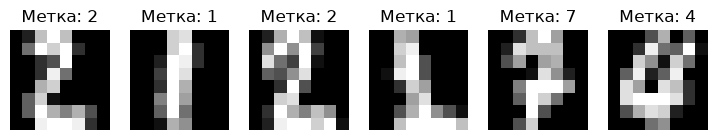

Обучение: 1347 · валидация: 450


In [2]:
digits = load_digits()
train_idx, val_idx = train_test_split(
    np.arange(len(digits.target)), test_size=450, stratify=digits.target, random_state=SEED
)
x = torch.tensor(digits.data / 16, dtype=torch.float32)
y = torch.tensor(digits.target, dtype=torch.long)
train = x[train_idx], y[train_idx]
val = x[val_idx], y[val_idx]

fig, axes = plt.subplots(1, 6, figsize=(9, 2))
for ax, index in zip(axes, train_idx[:6]):
    ax.imshow(digits.images[index], cmap='gray', vmin=0, vmax=16)
    ax.set_title(f'Метка: {y[index].item()}')
    ax.axis('off')
plt.show()
print(f'Обучение: {len(train_idx)} · валидация: {len(val_idx)}')

### Готовый цикл обучения

По каждой эпохе сохраняем потери. Обе кривые, обучающую и валидационную,
измеряем в режиме eval(), где dropout выключен. В каждом сравнении
заново создаём модель и оптимизатор. Один seed даёт одинаковые начальные
веса, отдельный генератор — одинаковый порядок батчей.

In [3]:
loss_fn = nn.CrossEntropyLoss()


def make_model(width=64, dropout=0.0):
    torch.manual_seed(SEED)
    return nn.Sequential(
        nn.Linear(64, width), nn.ReLU(), nn.Dropout(dropout), nn.Linear(width, 10)
    )


@torch.no_grad()
def evaluate(model, data):
    model.eval()
    xb, yb = data
    return loss_fn(model(xb), yb).item()


def fit(model, data, *, lr, epochs, batch_size, optimizer_cls,
        validation=None, weight_decay=0.0, schedule=None):
    torch.manual_seed(SEED)
    order_rng = torch.Generator().manual_seed(SEED)
    opt = optimizer_cls(model.parameters(), lr=lr, weight_decay=weight_decay)

    xb, yb = data
    history = {'train': [], 'val': [], 'lr': [], 'stopped': None, 'best_weights': None}
    best_val = float('inf')
    for epoch in range(1, epochs + 1):
        model.train()
        order = torch.randperm(len(xb), generator=order_rng)
        for indices in order.split(batch_size):
            if schedule is not None:
                opt.param_groups[0]['lr'] = schedule(len(history['lr']))
            history['lr'].append(opt.param_groups[0]['lr'])
            opt.zero_grad()
            loss = loss_fn(model(xb[indices]), yb[indices])
            if not torch.isfinite(loss):
                history['stopped'] = epoch
                return history
            loss.backward()
            opt.step()

        train_loss = evaluate(model, data)
        val_loss = evaluate(model, validation) if validation is not None else None
        if not np.isfinite(train_loss) or (val_loss is not None and not np.isfinite(val_loss)):
            history['stopped'] = epoch
            return history
        history['train'].append(train_loss)
        if val_loss is not None:
            history['val'].append(val_loss)
            if val_loss < best_val:
                best_val = val_loss
                history['best_weights'] = {
                    name: value.detach().clone() for name, value in model.state_dict().items()
                }
    return history


def plot_history(ax, history, key, label, **style):
    values = history[key]
    ax.plot(range(1, len(values) + 1), values, label=label, **style)

## 1. Потери стоят или скачут: проверяем один батч

Фиксируем 16 цифр с правильными метками. Один батч здесь равен одному шагу
и одной эпохе. В учебном тесте сеть должна существенно снизить потери на
этих цифрах. Это проверка работы цикла, а качество на новых данных посмотрим
отдельно.

**Проверьте крайности.** Сравните скорости 0.0001 и 10 при одинаковых весах.
На логарифмической шкале видны и скачки, и малые потери. При численном сбое
график заканчивается на последнем конечном значении.

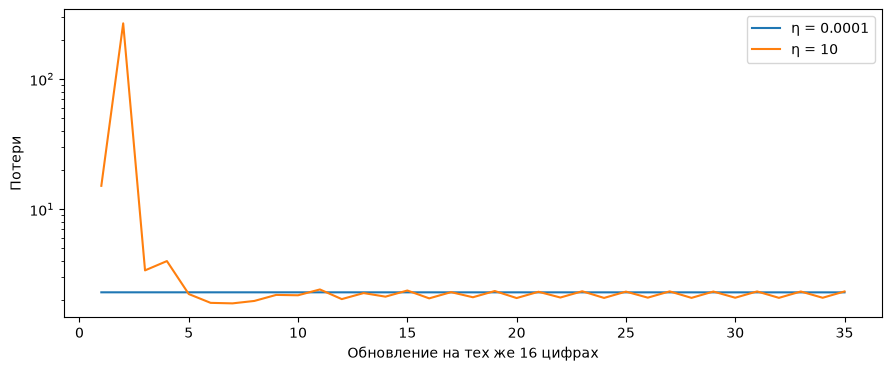

In [4]:
fixed_batch = train[0][:16], train[1][:16]


def run_on_one_batch(lr):
    return fit(make_model(), fixed_batch, lr=lr, epochs=35, batch_size=16,
               optimizer_cls=torch.optim.SGD)


def plot_one_batch(runs):
    fig, ax = plt.subplots(figsize=(8.8, 3.6), layout='constrained')
    for lr, run in runs.items():
        plot_history(ax, run, 'train', f'η = {lr:g}')
        if run['stopped'] is not None:
            ax.axvline(run['stopped'], color=RED, ls=':', alpha=.7)
            print(f'η={lr:g}: численный сбой на шаге {run["stopped"]}.')
    ax.set(xlabel='Обновление на тех же 16 цифрах', ylabel='Потери', yscale='log')
    ax.legend()
    plt.show()


extremes = {lr: run_on_one_batch(lr) for lr in (0.0001, 10.0)}
plot_one_batch(extremes)

**Как читать график.** Обе крайности мешают снижать потери: малый шаг даёт слабый прогресс, большой может давать скачки. Здесь менялась только скорость обучения.

### Рабочая скорость на одном батче

Добавим третий запуск со скоростью 0.3. Сравним его с двумя крайними
вариантами. В этом опыте рабочим считаем шаг, при котором потери упали
хотя бы вдвое относительно первого обновления. Для полного обучения
скорость подберём отдельно по валидации.

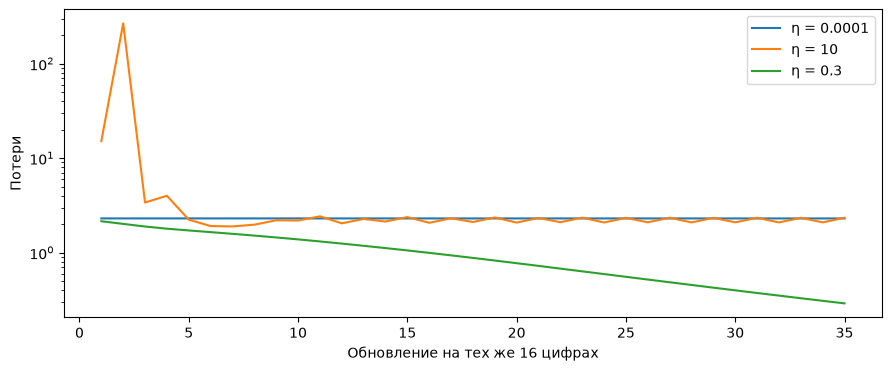

In [5]:
candidate_lr = 0.3
candidate = run_on_one_batch(candidate_lr)
plot_one_batch({**extremes, candidate_lr: candidate})

In [6]:
losses = candidate['train']
assert candidate['stopped'] is None and losses[-1] < losses[0] / 2
print(f'Потери: {losses[0]:.3f} → {losses[-1]:.3f}. Тест пройден.')

Потери: 2.150 → 0.290. Тест пройден.


## 2. На полном наборе: скорость, оптимизатор и расписание

Теперь используем все 1347 обучающих объектов и батч 64. У всех вариантов
одинаковые начальные веса и порядок батчей. Для каждого оптимизатора
пробуем три скорости, смотрим потери на валидации после восьми эпох и
затем обучаем лучшую настройку дольше с того же старта. У AdamW здесь
weight decay равен нулю: регуляризацию разберём отдельно.

SGD: η=0.01 → 2.208 · η=0.05 → 1.385 · η=0.2 → 0.297 | лучшая из проверенных η=0.2


SGD + momentum: η=0.003 → 1.942 · η=0.01 → 0.677 · η=0.05 → 0.167 | лучшая из проверенных η=0.05


AdamW: η=0.001 → 0.710 · η=0.003 → 0.235 · η=0.01 → 0.127 | лучшая из проверенных η=0.01


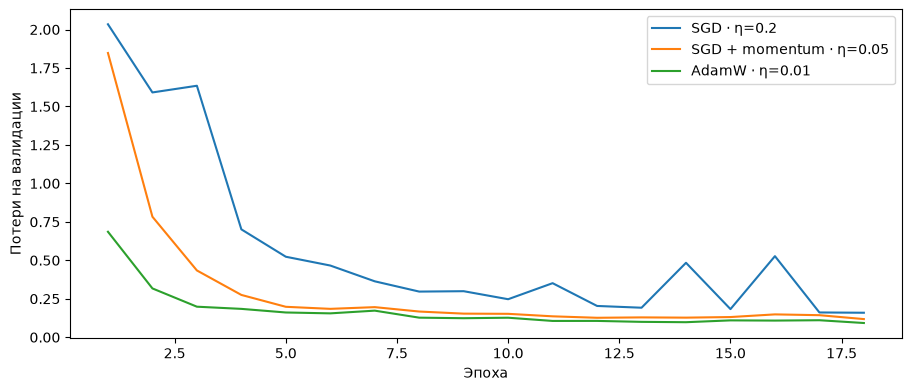

In [7]:
optimizers = {
    'SGD': (torch.optim.SGD, (0.01, 0.05, 0.2)),
    'SGD + momentum': (partial(torch.optim.SGD, momentum=0.9), (0.003, 0.01, 0.05)),
    'AdamW': (torch.optim.AdamW, (0.001, 0.003, 0.01)),
}


def full_run(optimizer_cls, lr, epochs, schedule=None):
    return fit(make_model(), train, validation=val, batch_size=64,
               optimizer_cls=optimizer_cls, lr=lr, epochs=epochs, schedule=schedule)


selected = {}
full_histories = {}
for name, (optimizer_cls, rates) in optimizers.items():
    scores = {rate: full_run(optimizer_cls, rate, 8)['val'][-1] for rate in rates}
    lr = min(scores, key=scores.get)
    print(f'{name}: ' + ' · '.join(f'η={rate:g} → {value:.3f}' for rate, value in scores.items())
          + f' | лучшая из проверенных η={lr:g}')
    selected[name] = lr
    full_histories[name] = full_run(optimizer_cls, lr, 18)

fig, ax = plt.subplots(figsize=(9, 3.8), layout='constrained')
for name, run in full_histories.items():
    plot_history(ax, run, 'val', f'{name} · η={selected[name]:g}')
ax.set(xlabel='Эпоха', ylabel='Потери на валидации')
ax.legend()
plt.show()

Скорости подобраны отдельно: одинаковое число η не означает одинаковый
размер изменения весов. График показывает, какой вариант быстрее снизил
потери при данном бюджете. В этом прогоне каждый победитель оказался
на верхней границе своей сетки. Следующим опытом можно проверить чуть
более высокие скорости при том же бюджете.

### Прогрев и косинусное снижение

Сравним два запуска AdamW по 18 эпох. В первом скорость постоянная.
Во втором первый проход по данным служит прогревом: скорость растёт
до выбранного пика. Затем она плавно уменьшается по косинусу. На левом
графике один шаг — одно обновление на батче, на правом одна точка — эпоха.

Постоянная: конец 0.093, минимум 0.093
Прогрев + косинус: конец 0.114, минимум 0.113


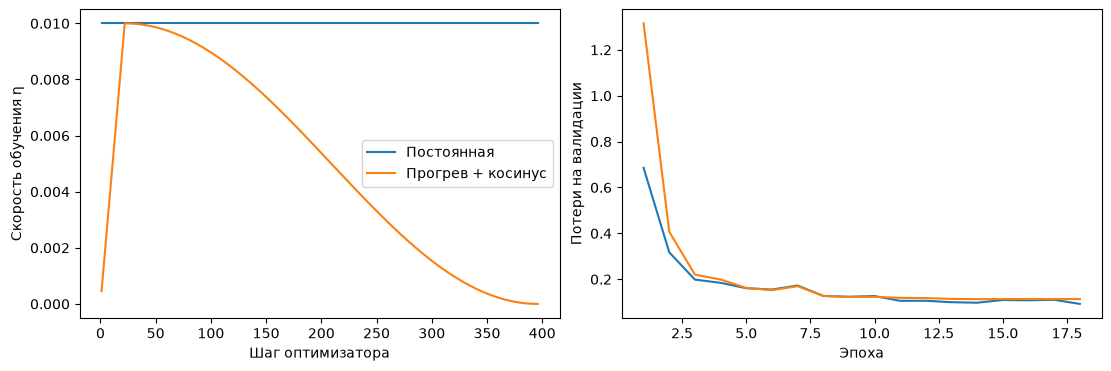

In [8]:
peak = selected['AdamW']
steps_per_epoch = (len(train[0]) + 63) // 64
total_steps = 18 * steps_per_epoch


def warmup_cosine(step):
    if step < steps_per_epoch:
        return peak * (step + 1) / steps_per_epoch
    progress = (step - steps_per_epoch + 1) / (total_steps - steps_per_epoch)
    return peak * 0.5 * (1 + np.cos(np.pi * progress))


constant = full_histories['AdamW']
scheduled = full_run(torch.optim.AdamW, peak, 18, schedule=warmup_cosine)
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6), layout='constrained')
for label, history in [('Постоянная', constant), ('Прогрев + косинус', scheduled)]:
    plot_history(axes[0], history, 'lr', label)
    plot_history(axes[1], history, 'val', label)
    print(f'{label}: конец {history["val"][-1]:.3f}, минимум {min(history["val"]):.3f}')
axes[0].set(xlabel='Шаг оптимизатора', ylabel='Скорость обучения η')
axes[1].set(xlabel='Эпоха', ylabel='Потери на валидации')
axes[0].legend()
plt.show()

Сравниваем кривые при одинаковом пике и числе шагов. Прогрев уменьшает
первые обновления, косинус меняет поздние. На этом небольшом наборе такой
режим может и уступить постоянной скорости. Если нужно отделить вклад
прогрева от снижения скорости, сравните эти изменения по одному.

## 3. Затухание и рост градиента

Берём MLP с восемью скрытыми слоями. Сравниваем Sigmoid и ReLU на тех же
16 цифрах, при одинаковых стартовых весах. Делаем один обратный проход
и пока не меняем веса. Для каждого слоя считаем типичный размер градиента
одного веса: корень из среднего квадрата (RMS). Последняя точка графика —
выходной слой. Большой перепад между началом и концом показывает,
насколько слабый сигнал получают ранние слои.

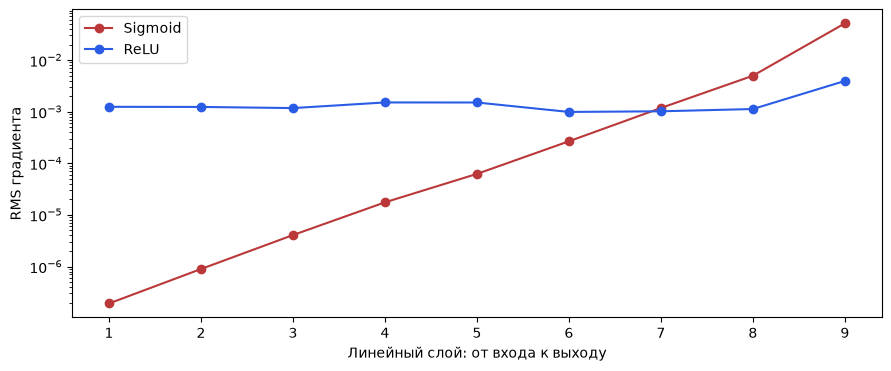

In [9]:
def deep_model(activation, gain=1.0):
    torch.manual_seed(SEED)
    layers = []
    for i in range(9):
        linear = nn.Linear(64, 10 if i == 8 else 64)
        nn.init.normal_(linear.weight, std=gain / np.sqrt(64))
        nn.init.zeros_(linear.bias)
        layers.append(linear)
        if i < 8:
            layers.append(activation())
    return nn.Sequential(*layers)


def gradient_profile(activation):
    model = deep_model(activation)
    xb, yb = fixed_batch
    loss_fn(model(xb), yb).backward()
    return np.array([
        layer.weight.grad.square().mean().sqrt().item()
        for layer in model if isinstance(layer, nn.Linear)
    ])


sigmoid_grad = gradient_profile(nn.Sigmoid)
relu_grad = gradient_profile(nn.ReLU)
layers = np.arange(1, len(sigmoid_grad) + 1)
fig, ax = plt.subplots(figsize=(8.8, 3.6), layout='constrained')
ax.plot(layers, sigmoid_grad, 'o-', color=RED, label='Sigmoid')
ax.plot(layers, relu_grad, 'o-', color=BLUE, label='ReLU')
ax.set(xlabel='Линейный слой: от входа к выходу', ylabel='RMS градиента',
       yscale='log', xticks=layers)
ax.legend()
plt.show()

### Насколько ослабел сигнал

Для каждой кривой делим RMS первого слоя на RMS выходного. Чем меньше
отношение, тем слабее сигнал в начале сети относительно выхода.

In [10]:
sigmoid_ratio = sigmoid_grad[0] / sigmoid_grad[-1]
relu_ratio = relu_grad[0] / relu_grad[-1]

In [11]:
print(f'Первый слой / выход: Sigmoid {sigmoid_ratio:.2e}, ReLU {relu_ratio:.2e}')
assert sigmoid_ratio < relu_ratio

Первый слой / выход: Sigmoid 3.73e-06, ReLU 3.16e-01


**Почему увеличение скорости может не помочь.** Скорость умножит шаги всех слоёв. Можно раскачать выходные слои раньше, чем ранние получат достаточный шаг. В этом примере ReLU лучше проводит сигнал; результат зависит и от инициализации.

### Демонстрация. Если градиент слишком большой

Увеличим разброс стартовых весов ReLU-сети в три раза. Сравним общую
норму градиента при двух вариантах инициализации и после обрезки
(gradient clipping) до 1. Обрезка уменьшает длину градиента и сохраняет
направление. Здесь причина всплеска задана заранее: слишком широкий
разброс весов.

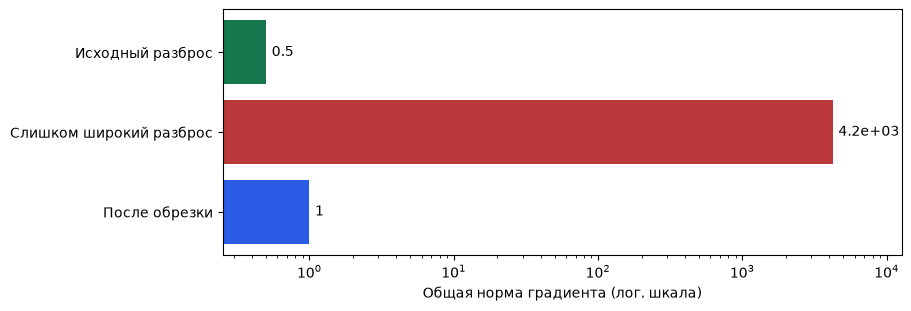

In [12]:
def gradients_at_start(gain):
    model = deep_model(nn.ReLU, gain)
    loss_fn(model(fixed_batch[0]), fixed_batch[1]).backward()
    return model


def grad_norm(model):
    return float(torch.stack([p.grad.norm() for p in model.parameters()]).norm())


normal = grad_norm(gradients_at_start(1.0))
wide = gradients_at_start(3.0)
before = float(nn.utils.clip_grad_norm_(wide.parameters(), max_norm=1.0))
after = grad_norm(wide)
fig, ax = plt.subplots(figsize=(9, 3), layout='constrained')
bars = ax.barh(['После обрезки', 'Слишком широкий разброс', 'Исходный разброс'],
               [after, before, normal], color=[BLUE, RED, GREEN])
ax.bar_label(bars, fmt='%.2g', padding=4)
ax.set(xlabel='Общая норма градиента (лог. шкала)', xscale='log')
ax.set_xlim(min(normal, after) / 2, before * 3)
plt.show()

**Если почти каждый шаг требует обрезки.** Смотреть норму до обрезки и искать причину. В примере сначала проверили бы инициализацию; для сбоя после первых обновлений стоит проверить скорость и данные.

## 4. Потери на обучении падают, а на валидации растут

Обучаем MLP шириной 128 на 80 цифрах. Для наглядности намеренно портим
метки у 16 случайно выбранных обучающих цифр. Так сеть может запомнить
неверные ответы. Валидация остаётся чистой.

Все варианты обучаем через AdamW с одинаковыми начальными весами,
скоростью, порядком батчей и числом эпох. Базовый запуск использует нулевой
weight decay и выключенный dropout. Дальше меняем по одному параметру:

- **Dropout** случайно обнуляет часть активаций при обучении.
- **Weight decay** добавляет к шагу AdamW движение весов к нулю.

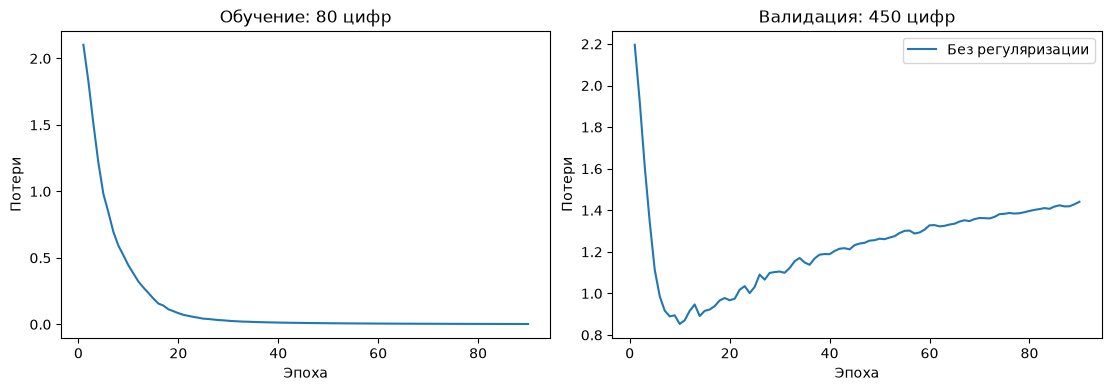

In [13]:
small_idx, _ = train_test_split(
    np.arange(len(train[1])), train_size=80, stratify=train[1].numpy(), random_state=SEED
)
small_x = train[0][small_idx]
small_y = train[1][small_idx].clone()
wrong = torch.randperm(len(small_y), generator=torch.Generator().manual_seed(SEED))[:16]
small_y[wrong] = (small_y[wrong] + 1) % 10
small_train = small_x, small_y
epochs = 90


def small_run(dropout=0.0, decay=0.0):
    return fit(make_model(width=128, dropout=dropout), small_train, validation=val,
               optimizer_cls=torch.optim.AdamW, weight_decay=decay, lr=0.01,
               epochs=epochs, batch_size=16)


def plot_regularization(runs):
    fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), layout='constrained')
    for label, history in runs.items():
        for ax, key, title in zip(axes, ['train', 'val'], ['Обучение: 80 цифр', 'Валидация: 450 цифр']):
            plot_history(ax, history, key, label)
            ax.set(title=title, xlabel='Эпоха', ylabel='Потери')
    axes[1].legend()
    plt.show()


baseline = small_run()
plot_regularization({'Без регуляризации': baseline})

**Что выбрать при переобучении.** Для выбора по потерям берём веса эпохи с минимумом на валидации. Дальнейшее падение потерь на обучении может означать запоминание испорченных меток.

### Что именно меняет dropout

Те же четыре выхода скрытого слоя из лекции пропускаем через dropout
с вероятностью 0.5. На обучении маска меняется от прохода к проходу.
Оставшиеся числа удваиваются, чтобы сохранить среднее в серии проходов.
При предсказании все четыре значения остаются прежними.

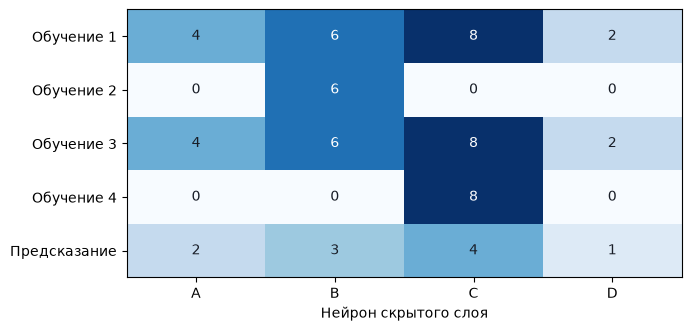

In [14]:
activations = torch.tensor([2., 3., 4., 1.])
mask_layer = nn.Dropout(0.5)
with torch.random.fork_rng(devices=[]):
    torch.manual_seed(SEED)
    mask_layer.train()
    passes = [mask_layer(activations).numpy() for _ in range(4)]
mask_layer.eval()
passes.append(mask_layer(activations).numpy())

fig, ax = plt.subplots(figsize=(6.8, 3.2), layout='constrained')
ax.imshow(passes, cmap='Blues', vmin=0, vmax=8, aspect='auto')
for row, values in enumerate(passes):
    for col, value in enumerate(values):
        ax.text(col, row, f'{value:g}', ha='center', va='center',
                color='white' if value >= 6 else '#181d27')
ax.set(xticks=range(4), xticklabels=['A', 'B', 'C', 'D'],
       yticks=range(5), yticklabels=['Обучение 1', 'Обучение 2', 'Обучение 3',
                                    'Обучение 4', 'Предсказание'],
       xlabel='Нейрон скрытого слоя')
plt.show()

### Отдельные запуски с dropout и weight decay

Сравниваем dropout с вероятностью 0.4, weight decay с коэффициентом 0.2
и базовый вариант. В каждом запуске изменена только одна настройка.
Эти значения выбраны для демонстрации; удобная настройка зависит от данных.

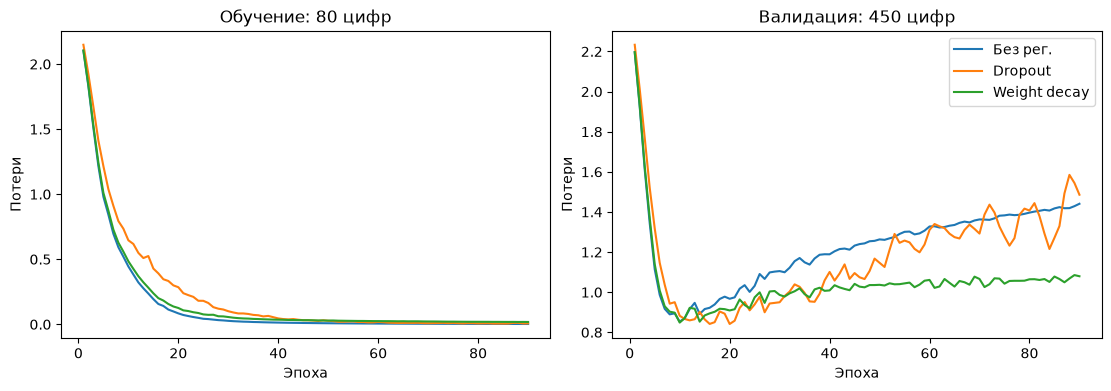

In [15]:
dropout_run = small_run(dropout=0.4)
decay_run = small_run(decay=0.2)
plot_regularization({'Без рег.': baseline, 'Dropout': dropout_run, 'Weight decay': decay_run})

In [16]:
for run in (dropout_run, decay_run):
    assert run['stopped'] is None and len(run['val']) == epochs
    assert np.isfinite(run['val']).all()
    assert not np.allclose(run['val'], baseline['val'])
assert not np.allclose(dropout_run['val'], decay_run['val'])
print('Получены три разные кривые.')

Получены три разные кривые.


### Выбор и восстановление лучших весов

По ходу обучения сохраняем копию весов, когда потери на валидации
улучшаются. Таблица сравнивает три минимума и потери на последней эпохе.
Затем загружаем веса лучшего варианта в новую модель и проверяем, что
потери совпадают с зафиксированным минимумом.

In [17]:
def best_epoch(history):
    return int(np.argmin(history['val'])) + 1

In [18]:
print(f'{"Режим":22} {"Эпоха":>5} {"Мин. потери":>13} {"Потери в конце":>17}')
for name, run in [('Без регуляризации', baseline), ('Dropout', dropout_run),
                  ('Weight decay', decay_run)]:
    epoch = best_epoch(run)
    assert 1 <= epoch <= epochs
    print(f'{name:22} {epoch:5d} {run["val"][epoch-1]:14.3f} {run["val"][-1]:15.3f}')

Режим                  Эпоха   Мин. потери    Потери в конце
Без регуляризации         10          0.853           1.441
Dropout                   20          0.842           1.486
Weight decay              10          0.848           1.080


In [19]:
variants = {'Без регуляризации': baseline, 'Dropout': dropout_run,
            'Weight decay': decay_run}
winner = min(variants, key=lambda name: min(variants[name]['val']))
chosen = variants[winner]
restored = make_model(width=128, dropout=0.4 if winner == 'Dropout' else 0.0)
restored.load_state_dict(chosen['best_weights'])
restored_loss = evaluate(restored, val)
assert np.isclose(restored_loss, min(chosen['val']))
print(f'Восстановили вариант «{winner}», эпоха {best_epoch(chosen)}. '
      f'Потери на валидации: {restored_loss:.3f}.')

Восстановили вариант «Dropout», эпоха 20. Потери на валидации: 0.842.


**Как читать итоговую таблицу.** Вариант и номер эпохи выбираем по минимуму валидационных потерь. Последняя эпоха показывает результат при одинаковом бюджете без выбора чекпойнта. Один seed даёт учебное сравнение, для устойчивого вывода повторите запуски.

## 5. Как батч влияет на нормализацию

Повторим пример из лекции на одном объекте с ответами четырёх нейронов
(1, 3, 2, 4). Сначала поместим его рядом с объектом, у которого все
значения больше, затем рядом с объектом, у которого все значения меньше.
В выводе сравниваем первый объект после нормализации.

BatchNorm считаем в режиме обучения. LayerNorm в обоих запусках считает
среднее и разброс только по четырём ответам первого объекта.

In [20]:
sample = torch.tensor([1., 3., 2., 4.])
batch_high = torch.stack((sample, sample + 2))
batch_low = torch.stack((sample, sample - 2))
batch_norm = nn.BatchNorm1d(4, affine=False)
layer_norm = nn.LayerNorm(4, elementwise_affine=False)

for name, norm in [('BatchNorm', batch_norm), ('LayerNorm', layer_norm)]:
    print(name)
    print('  с большим соседом:', norm(batch_high)[0].numpy().round(2))
    print('  с меньшим соседом:', norm(batch_low)[0].numpy().round(2))

BatchNorm
  с большим соседом: [-1. -1. -1. -1.]
  с меньшим соседом: [1. 1. 1. 1.]
LayerNorm
  с большим соседом: [-1.34  0.45 -0.45  1.34]
  с меньшим соседом: [-1.34  0.45 -0.45  1.34]


**Что изменилось при смене соседа.** BatchNorm берёт каждый столбец по двум объектам. Поэтому сосед влияет на среднее столбца. LayerNorm берёт строку первого объекта, которая осталась той же.

### Один батч из 64 объектов или четыре порции по 16

Сравним два способа сделать одно обновление. В первом сразу считаем
средние потери по 64 объектам. Во втором четыре раза считаем средние
потери по порции из 16, каждый раз делим потери на 4 и вызываем backward.
Веса обновляем только после последней порции.

Для нашей MLP с выключенным dropout оба способа дают одинаковый шаг
с точностью до округления. BatchNorm меняет этот результат: статистика
каждой порции отличается от статистики всех 64 объектов.

In [21]:
xb, yb = train[0][:64], train[1][:64]
whole, split = make_model(), make_model()
whole_opt = torch.optim.SGD(whole.parameters(), lr=0.1)
split_opt = torch.optim.SGD(split.parameters(), lr=0.1)

whole_opt.zero_grad()
loss_fn(whole(xb), yb).backward()
whole_opt.step()

split_opt.zero_grad()
for part_x, part_y in zip(xb.split(16), yb.split(16)):
    (loss_fn(split(part_x), part_y) / 4).backward()
split_opt.step()

max_diff = max(float((a - b).detach().abs().max())
               for a, b in zip(whole.parameters(), split.parameters()))
assert max_diff < 1e-6
print(f'Максимальная разница весов после одного обновления: {max_diff:.2e}.')

Максимальная разница весов после одного обновления: 7.45e-09.


## Итоги занятия

| Симптом | Первая проверка | Следующее действие |
|---|---|---|
| Потери стоят или скачут | Тест на одном батче | Проверьте шаг обучения и подберите скорость |
| Сигнал до ранних слоёв почти не доходит | Сравните градиенты по слоям | Проверьте активации и инициализацию |
| Большая норма градиента | Посмотрите норму до обрезки | Ищите причину, при отдельных выбросах проверьте clipping |
| Потери на обучении падают, на валидации растут | Найдите эпоху с минимумом на валидации | Проверьте dropout или weight decay по одному |

Для честного сравнения меняем по одной настройке. При подборе скорости
фиксируем батч и оптимизатор, при сравнении регуляризации сохраняем
одно и то же разбиение и сравниваем по одним и тем же потерям на валидации.